In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import matplotlib.patches as mpatches
import matplotlib.lines as mlines
import folium 
from shapely.geometry import box
import requests
import os
import warnings
warnings.filterwarnings("ignore")

print("All modules succesfully imported")

All modules succesfully imported


Creating a path for our data so that it can be easily accessed

In [4]:
DATA = "C:/Users/TEDSON/chimaliro-schoolsite-accessibility/data"

ta_path = f"{DATA}/mw_ta.geojson"
small_roads_path = f"{DATA}/thyolo_roads.geojson"

ta_raw = gpd.read_file(ta_path)
print(ta_raw.columns.tolist) #Checking the columns in the ta_raw GeoDataFrame

<bound method IndexOpsMixin.tolist of Index(['AREA', 'PERIMETER', 'MW_DIST_BN', 'MW_DIST__1', 'TA_NAME', 'geometry'], dtype='str')>


Loading shape files to be used in the project

In [5]:
#load the ta boundary and filter for chimaliro
print("Loading TA boundary...")
ta_raw = gpd.read_file(ta_path)
name_col = "TA_NAME"
ta = ta_raw[ta_raw[name_col].astype(str).str.upper().str.contains("CHIMALIRO", na=False)].copy()
print(f"found {len(ta)} TA feature(s) for Chimaliro")


print("\nloading data and fixing CRS...")
prot_raw = gpd.read_file(f"{DATA}/mw_protected_areas.geojson")
roads_small = gpd.read_file(small_roads_path)
sch_mw = gpd.read_file(f"{DATA}/mw_primary_schools.geojson")

UTM_CRS = "EPSG:32736"  # UTM Zone 36N

ta = ta.to_crs(UTM_CRS)
prot_ta = gpd.clip(prot_raw.to_crs(UTM_CRS), ta)

roads_ta = roads_small.to_crs(UTM_CRS)


school_ta = gpd.clip(sch_mw.to_crs(UTM_CRS), ta)


print("\n ...Cleaned Data check...")
print(f"Protected areas within TA: {len(prot_ta)}")
print(f"Roads within TA: {len(roads_ta)}")
print(f"Schools within TA: {len(school_ta)}") 

Loading TA boundary...
found 1 TA feature(s) for Chimaliro

loading data and fixing CRS...

 ...Cleaned Data check...
Protected areas within TA: 0
Roads within TA: 409
Schools within TA: 29


In [10]:
print(school_ta.head())

                  X             Y District  EMIS_Numbe             School_Nam  \
4968  730615.129434  8.227533e+06   Thyolo    502367.0                Nasonia   
4956  724398.360960  8.232746e+06   Thyolo    502245.0         Namaona School   
4934  746546.273699  8.224969e+06   Thyolo    501632.0         Matumbo School   
5044  747005.108052  8.229043e+06   Thyolo    505060.0  Ennockie View Academy   
4924  747735.297942  8.229648e+06   Thyolo    501370.0        Luchenza School   

         X_Coordina    Y_Coordina  male_stude  female_stu            Type  \
4968  730639.153976  8.227510e+06        96.0       117.0  Primary school   
4956  724422.386907  8.232723e+06       623.0       605.0  Primary school   
4934  746570.296030  8.224945e+06       277.0       289.0  Primary school   
5044  747029.130920  8.229020e+06         0.0         0.0  Primary school   
4924  747759.320814  8.229625e+06      1135.0      1246.0  Primary school   

         Long      Lat  No_of_Teac     r          

In [11]:
print(school_ta.columns.tolist())

['X', 'Y', 'District', 'EMIS_Numbe', 'School_Nam', 'X_Coordina', 'Y_Coordina', 'male_stude', 'female_stu', 'Type', 'Long', 'Lat', 'No_of_Teac', 'r', 'geometry']


Lets visualize our imported data on a map

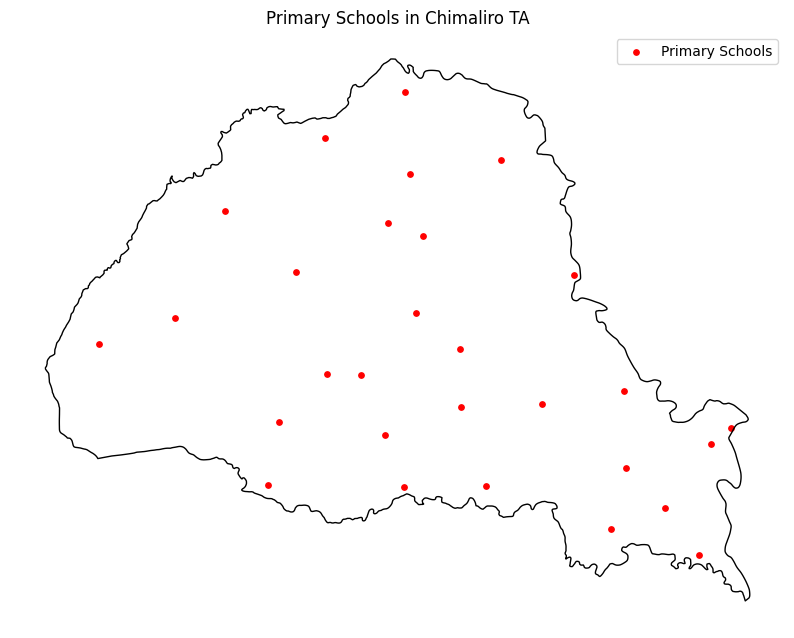

In [ ]:
fig, ax = plt.subplots(figsize=(10, 9))

# Plot Chimaliro TA boundary
ta.boundary.plot(
    ax=ax,
    color="black",
    linewidth=1
)

# Plot primary schools
school_ta.plot(
    ax=ax,
    color="red",
    markersize=15,
    label="Primary Schools"
)

ax.set_title("Schools in Chimaliro TA")

ax.legend()
ax.set_axis_off()

plt.show()